In [3]:
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
get_ipython().run_line_magic('matplotlib', 'inline')

pd.set_option('display.max_rows', 150)
pd.set_option('display.max_columns', 12)
pd.set_option('display.width', 160)
pd.set_option('display.float_format', lambda v: f'{v:.8e}')
plt.rcParams.update({'figure.figsize': (9, 5), 'font.size': 11,
                     'axes.grid': True, 'grid.alpha': 0.25,
                     'figure.dpi': 110})

In [4]:
def grid_1d(h):
    N = int(round(1.0 / h))
    if N < 2 or not np.isclose(N * h, 1.0):
        raise ValueError('h must divide [0, 1] into at least two intervals.')
    return np.linspace(0.0, 1.0, N + 1)

def time_grid(T, k):
    M = int(round(T / k))
    if M < 1 or not np.isclose(M * k, T):
        raise ValueError('k must divide T; no unreported shortened time step is used.')
    return np.linspace(0.0, T, M + 1)

def second_difference(h, alpha=0.0):
    # u_x(0)=g0(t), u_x(1)+alpha*u(1)=g1(t).
    size = len(grid_1d(h))
    lower = np.ones(size - 1) / h**2
    diagonal = -2.0 * np.ones(size) / h**2
    upper = np.ones(size - 1) / h**2
    upper[0] = 2.0 / h**2
    lower[-1] = 2.0 / h**2
    diagonal[-1] -= 2.0 * alpha / h
    return lower, diagonal, upper

def boundary_source(size, h, g0, g1):
    b = np.zeros(size)
    b[0], b[-1] = -2.0 * g0 / h, 2.0 * g1 / h
    return b

### Tridiagonal solution: Thomas algorithm
For $a_i z_{i-1}+d_i z_i+c_i z_{i+1}=q_i$, forward elimination uses
$$\widetilde d_0=d_0,\qquad c'_0=c_0/\widetilde d_0,$$
$$\widetilde d_i=d_i-a_i c'_{i-1},\qquad c'_i=c_i/\widetilde d_i.$$
For each right-hand side,
$$q'_0=q_0/\widetilde d_0,\qquad
q'_i=(q_i-a_iq'_{i-1})/\widetilde d_i,$$
followed by $z_{N}=q'_{N}$ and $z_i=q'_i-c'_i z_{i+1}$.

The matrices here are strictly diagonally dominant after adding the identity in each implicit step, so no pivoting is needed. The factorisation is reused at every time step. A two-dimensional right-hand-side array solves all independent grid lines in one call.

In [5]:
def tri_apply(operator, values):
    # Operate on axis 0; other axes represent independent right-hand sides.
    lower, diagonal, upper = operator
    scale = (-1,) + (1,) * (values.ndim - 1)
    result = diagonal.reshape(scale) * values
    result[1:] += lower.reshape(scale) * values[:-1]
    result[:-1] += upper.reshape(scale) * values[1:]
    return result

class ThomasFactor:
    # Factor once; reuse for all time steps and all line solves.
    def __init__(self, lower, diagonal, upper):
        self.lower = np.asarray(lower, dtype=float).copy()
        self.pivot = np.asarray(diagonal, dtype=float).copy()
        self.upper_ratio = np.zeros(len(diagonal) - 1)
        for i in range(len(diagonal) - 1):
            if abs(self.pivot[i]) < 1e-14:
                raise ArithmeticError('Zero pivot in Thomas algorithm.')
            self.upper_ratio[i] = upper[i] / self.pivot[i]
            self.pivot[i + 1] -= self.lower[i] * self.upper_ratio[i]
        if abs(self.pivot[-1]) < 1e-14:
            raise ArithmeticError('Zero final pivot in Thomas algorithm.')

    def solve(self, rhs):
        answer = np.array(rhs, dtype=float, copy=True)
        answer[0] /= self.pivot[0]
        for i in range(1, len(self.pivot)):
            answer[i] = (answer[i] - self.lower[i - 1] * answer[i - 1]) / self.pivot[i]
        for i in range(len(self.pivot) - 2, -1, -1):
            answer[i] -= self.upper_ratio[i] * answer[i + 1]
        return answer

def implicit_factor(operator, a):
    lower, diagonal, upper = operator
    return ThomasFactor(-a * lower, 1.0 - a * diagonal, -a * upper)

## 2. Crank-Nicolson time discretisation
Apply the trapezoidal rule to $\dot U=LU+b(t)$:
$$\boxed{\left(I-\frac{k}{2}L\right)U^{n+1}
=\left(I+\frac{k}{2}L\right)U^n+\frac{k}{2}[b(t_n)+b(t_{n+1})].}$$
For an interior row this is
$$-\frac r2 U_{i-1}^{n+1}+(1+r)U_i^{n+1}-\frac r2 U_{i+1}^{n+1}
=\frac r2 U_{i-1}^n+(1-r)U_i^n+\frac r2 U_{i+1}^n.$$
The left boundary row is
$$(1+r)U_0^{n+1}-rU_1^{n+1}
=(1-r)U_0^n+rU_1^n-\frac{k}{h}[g_0(t_n)+g_0(t_{n+1})].$$
The right row is
$$-rU_{N-1}^{n+1}+(1+r+k\alpha/h)U_N^{n+1}
=rU_{N-1}^{n}+(1-r-k\alpha/h)U_N^{n}
+\frac{k}{h}[g_1(t_n)+g_1(t_{n+1})].$$
The implementation assembles these same rows through $L$ and $b$.

In [6]:
def cn_heat(h, k, T, initial, g0, g1, alpha=0.0):
    x, times = grid_1d(h), time_grid(T, k)
    L = second_difference(h, alpha)
    factor = implicit_factor(L, k / 2.0)
    U = np.empty((len(times), len(x)))
    U[0] = initial(x)
    for n in range(len(times) - 1):
        bn = boundary_source(len(x), h, g0(times[n]), g1(times[n]))
        bnext = boundary_source(len(x), h, g0(times[n + 1]), g1(times[n + 1]))
        rhs = U[n] + (k / 2.0) * (tri_apply(L, U[n]) + bn + bnext)
        U[n + 1] = factor.solve(rhs)
    return x, times, U

def mixed_cn(h, k, T=0.5):
    return cn_heat(h, k, T, np.sin,
                   lambda t: np.exp(-t),
                   lambda t: (np.cos(1.0) + np.sin(1.0)) * np.exp(-t),
                   alpha=1.0)

In [7]:
def time_index(times, requested):
    j = int(np.argmin(np.abs(times - requested)))
    if not np.isclose(times[j], requested, atol=1e-12, rtol=0):
        raise ValueError('Requested time is not on the time grid.')
    return j

def value_table(x, numerical, exact_values):
    error = numerical - exact_values
    return pd.DataFrame({'x': x, 'computed U': numerical,
                         'exact u': exact_values, 'signed error': error,
                         'absolute error': np.abs(error)})

def show_1d_tables(x, times, U, exact, requested, h, k):
    for t in requested:
        j = time_index(times, t)
        display(Markdown(f'**t = {t:g}; h = {h:g}, k = {k:g}, r = {k/h**2:g}**'))
        display(value_table(x, U[j], exact(x, t)))

def profile_plot(x, times, U, exact, requested, title):
    fig, ax = plt.subplots(figsize=(10, 5))
    for color, t in zip(['tab:blue', 'tab:orange', 'tab:green'], requested):
        j = time_index(times, t)
        xf = np.linspace(0, 1, 401)
        ax.plot(xf, exact(xf, t), color=color, lw=1.8, label=f'exact, t={t:g}')
        ax.plot(x, U[j], 'o', color=color, ms=4, mfc='none', label=f'computed, t={t:g}')
    ax.set(xlabel='x', ylabel='u(x,t)', title=title)
    ax.legend(ncol=2)
    fig.tight_layout()
    plt.show()

def convergence_table(rows):
    table = pd.DataFrame(rows)
    table['previous error / error'] = table['max error'].shift(1) / table['max error']
    table['observed p'] = np.log2(table['previous error / error'])
    return table

## Question 1 - Crank-Nicolson with homogeneous Neumann conditions
$$u_t=u_{xx},\quad u(x,0)=\cos(\pi x),\quad u_x(0,t)=u_x(1,t)=0.$$
The exact solution is $u(x,t)=e^{-\pi^2t}\cos(\pi x)$.

Use $h=0.1$, $k=0.005$, hence $\boxed{r=0.5}$. Here $\alpha=g_0=g_1=0$.

**t = 0.01; h = 0.1, k = 0.005, r = 0.5**

,x,computed U,exact u,signed error,absolute error
0,0.00000000e+00,9.06733666e-01,9.06018056e-01,7.15610153e-04,7.15610153e-04
1,1.00000000e-01,8.62354962e-01,8.61674376e-01,6.80585699e-04,6.80585699e-04
2,2.00000000e-01,7.33562945e-01,7.32984004e-01,5.78940775e-04,5.78940775e-04
3,3.00000000e-01,5.32964677e-01,5.32544052e-01,4.20625094e-04,4.20625094e-04
4,4.00000000e-01,2.80196112e-01,2.79974976e-01,2.21135699e-04,2.21135699e-04
5,5.00000000e-01,6.93889390e-18,5.54776056e-17,-4.85387117e-17,4.85387117e-17
6,6.00000000e-01,-2.80196112e-01,-2.79974976e-01,-2.21135699e-04,2.21135699e-04
7,7.00000000e-01,-5.32964677e-01,-5.32544052e-01,-4.20625094e-04,4.20625094e-04
8,8.00000000e-01,-7.33562945e-01,-7.32984004e-01,-5.78940775e-04,5.78940775e-04
9,9.00000000e-01,-8.62354962e-01,-8.61674376e-01,-6.80585699e-04,6.80585699e-04


**t = 0.05; h = 0.1, k = 0.005, r = 0.5**

,x,computed U,exact u,signed error,absolute error
0,0.00000000e+00,6.12912819e-01,6.10498025e-01,2.41479326e-03,2.41479326e-03
1,1.00000000e-01,5.82914730e-01,5.80618125e-01,2.29660487e-03,2.29660487e-03
2,2.00000000e-01,4.95856886e-01,4.93903277e-01,1.95360879e-03,1.95360879e-03
3,3.00000000e-01,3.60261116e-01,3.58841736e-01,1.41937987e-03,1.41937987e-03
4,4.00000000e-01,1.89400477e-01,1.88654265e-01,7.46212157e-04,7.46212157e-04
5,5.00000000e-01,0.00000000e+00,3.73822226e-17,-3.73822226e-17,3.73822226e-17
6,6.00000000e-01,-1.89400477e-01,-1.88654265e-01,-7.46212157e-04,7.46212157e-04
7,7.00000000e-01,-3.60261116e-01,-3.58841736e-01,-1.41937987e-03,1.41937987e-03
8,8.00000000e-01,-4.95856886e-01,-4.93903277e-01,-1.95360879e-03,1.95360879e-03
9,9.00000000e-01,-5.82914730e-01,-5.80618125e-01,-2.29660487e-03,2.29660487e-03


**t = 0.1; h = 0.1, k = 0.005, r = 0.5**

,x,computed U,exact u,signed error,absolute error
0,0.00000000e+00,3.75662123e-01,3.72707839e-01,2.95428427e-03,2.95428427e-03
1,1.00000000e-01,3.57275910e-01,3.54466219e-01,2.80969130e-03,2.80969130e-03
2,2.00000000e-01,3.03917042e-01,3.01526976e-01,2.39006618e-03,2.39006618e-03
3,3.00000000e-01,2.20808656e-01,2.19072171e-01,1.73648472e-03,1.73648472e-03
4,4.00000000e-01,1.16085980e-01,1.15173056e-01,9.12924044e-04,9.12924044e-04
5,5.00000000e-01,6.59194921e-17,2.28217731e-17,4.30977190e-17,4.30977190e-17
6,6.00000000e-01,-1.16085980e-01,-1.15173056e-01,-9.12924044e-04,9.12924044e-04
7,7.00000000e-01,-2.20808656e-01,-2.19072171e-01,-1.73648472e-03,1.73648472e-03
8,8.00000000e-01,-3.03917042e-01,-3.01526976e-01,-2.39006618e-03,2.39006618e-03
9,9.00000000e-01,-3.57275910e-01,-3.54466219e-01,-2.80969130e-03,2.80969130e-03


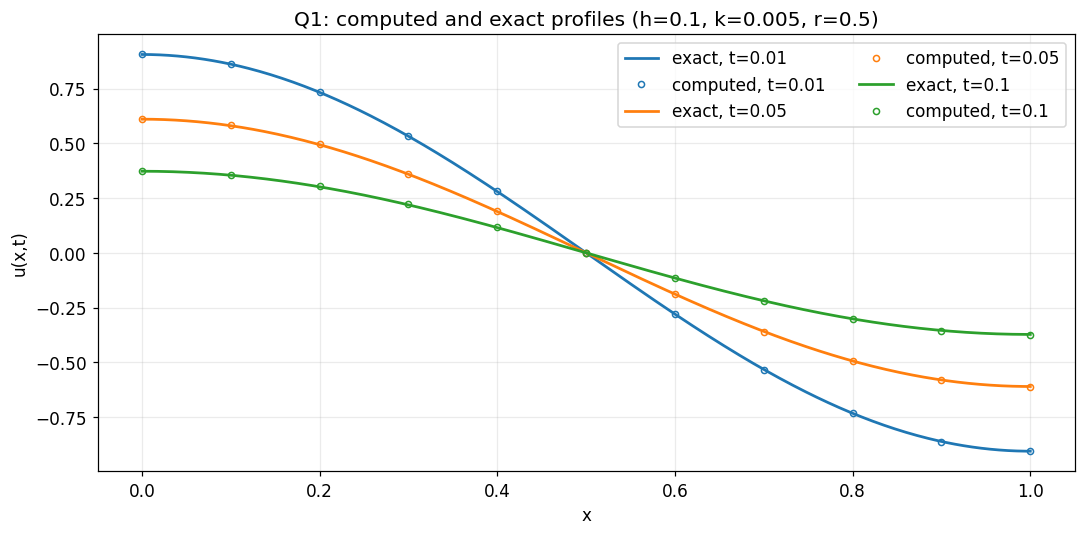

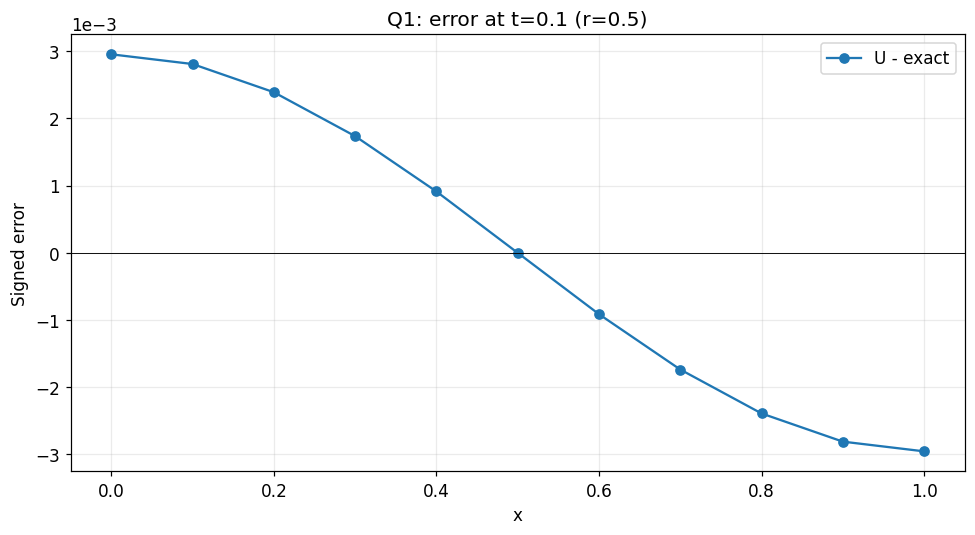

,t,r,max error
0,1.00000000e-02,5.00000000e-01,7.15610153e-04
1,5.00000000e-02,5.00000000e-01,2.41479326e-03
2,1.00000000e-01,5.00000000e-01,2.95428427e-03


In [11]:
h1, k1 = 0.1, 0.005
exact1 = lambda x, t: np.exp(-np.pi**2 * t) * np.cos(np.pi * x)
x1, times1, U1 = cn_heat(h1, k1, 0.1, lambda x: np.cos(np.pi*x),
                         lambda t: 0.0, lambda t: 0.0)
show_1d_tables(x1, times1, U1, exact1, [0.01, 0.05, 0.1], h1, k1)
profile_plot(x1, times1, U1, exact1, [0.01, 0.05, 0.1],
             'Q1: computed and exact profiles (h=0.1, k=0.005, r=0.5)')
fig, ax = plt.subplots()
ax.plot(x1, U1[-1] - exact1(x1, 0.1), 'o-', label='U - exact')
ax.axhline(0, color='black', lw=0.6)
ax.set(xlabel='x', ylabel='Signed error', title='Q1: error at t=0.1 (r=0.5)')
ax.ticklabel_format(axis='y', style='sci', scilimits=(0, 0))
ax.legend()
fig.tight_layout()
plt.show()
q1_summary = pd.DataFrame([{'t': t, 'r': k1/h1**2,
                            'max error': np.max(np.abs(U1[time_index(times1,t)] - exact1(x1,t)))}
                           for t in [0.01, 0.05, 0.1]])
display(q1_summary)

In [12]:
lambda_h1 = 4/h1**2 * np.sin(np.pi*h1/2)**2
q1 = (1-k1*lambda_h1/2)/(1+k1*lambda_h1/2)
modal1 = q1**np.arange(len(times1))[:, None] * np.cos(np.pi*x1)[None, :]
q1_modal_residual = np.max(np.abs(U1 - modal1))
assert q1_modal_residual < 1e-12
print(f'Q1 discrete-mode check: maximum difference = {q1_modal_residual:.3e}')

Q1 discrete-mode check: maximum difference = 1.277e-15


## Question 2 - Crank-Nicolson with mixed derivative conditions
$$u_t=u_{xx},\qquad u(x,0)=\sin x,$$
$$u_x(0,t)=e^{-t},\qquad u_x(1,t)+u(1,t)=(\cos1+\sin1)e^{-t}.$$
Thus $\alpha=1$, $g_0(t)=e^{-t}$, $g_1(t)=(\cos1+\sin1)e^{-t}$, and
$$u(x,t)=e^{-t}\sin x.$$
Use $h=0.05$, $k=0.05$, so $\boxed{r=20}$.
The boundary sources are evaluated at both ends of each time step in the CN formula.

**t = 0.1; h = 0.05, k = 0.05, r = 20**

,x,computed U,exact u,signed error,absolute error
0,0.00000000e+00,-1.22321674e-04,0.00000000e+00,-1.22321674e-04,1.22321674e-04
1,5.00000000e-02,4.51052762e-02,4.52230225e-02,-1.17746318e-04,1.17746318e-04
2,1.00000000e-01,9.02265511e-02,9.03330110e-02,-1.06459832e-04,1.06459832e-04
3,1.50000000e-01,1.35124867e-01,1.35217214e-01,-9.23467209e-05,9.23467209e-05
4,2.00000000e-01,1.79685783e-01,1.79763444e-01,-7.76615643e-05,7.76615643e-05
5,2.50000000e-01,2.23796739e-01,2.23860360e-01,-6.36210586e-05,6.36210586e-05
6,3.00000000e-01,2.67346947e-01,2.67397741e-01,-5.07942092e-05,5.07942092e-05
7,3.50000000e-01,3.10227410e-01,3.10266767e-01,-3.93565334e-05,3.93565334e-05
8,4.00000000e-01,3.52331034e-01,3.52360287e-01,-2.92534319e-05,2.92534319e-05
9,4.50000000e-01,3.93552787e-01,3.93573091e-01,-2.03036433e-05,2.03036433e-05


**t = 0.3; h = 0.05, k = 0.05, r = 20**

,x,computed U,exact u,signed error,absolute error
0,0.00000000e+00,-1.83126454e-04,0.00000000e+00,-1.83126454e-04,1.83126454e-04
1,5.00000000e-02,3.68485079e-02,3.70254793e-02,-1.76971356e-04,1.76971356e-04
2,1.00000000e-01,7.37954041e-02,7.39584141e-02,-1.63010013e-04,1.63010013e-04
3,1.50000000e-01,1.10559108e-01,1.10706491e-01,-1.47383306e-04,1.47383306e-04
4,2.00000000e-01,1.47045684e-01,1.47177860e-01,-1.32175755e-04,1.32175755e-04
5,2.50000000e-01,1.83163510e-01,1.83281361e-01,-1.17850850e-04,1.17850850e-04
6,3.00000000e-01,2.18822416e-01,2.18926754e-01,-1.04337202e-04,1.04337202e-04
7,3.50000000e-01,2.53933479e-01,2.54024944e-01,-9.14641657e-05,9.14641657e-05
8,4.00000000e-01,2.88409099e-01,2.88488203e-01,-7.91040492e-05,7.91040492e-05
9,4.50000000e-01,3.22163198e-01,3.22230393e-01,-6.71952089e-05,6.71952089e-05


**t = 0.5; h = 0.05, k = 0.05, r = 20**

,x,computed U,exact u,signed error,absolute error
0,0.00000000e+00,-1.99668168e-04,0.00000000e+00,-1.99668168e-04,1.99668168e-04
1,5.00000000e-02,3.01202111e-02,3.03138985e-02,-1.93687362e-04,1.93687362e-04
2,1.00000000e-01,6.03711532e-02,6.05520281e-02,-1.80874897e-04,1.80874897e-04
3,1.50000000e-01,9.04712623e-02,9.06388091e-02,-1.67546760e-04,1.67546760e-04
4,2.00000000e-01,1.20344099e-01,1.20499040e-01,-1.54941367e-04,1.54941367e-04
5,2.50000000e-01,1.49915126e-01,1.50058087e-01,-1.42960255e-04,1.42960255e-04
6,3.00000000e-01,1.79110712e-01,1.79242066e-01,-1.31353676e-04,1.31353676e-04
7,3.50000000e-01,2.07858047e-01,2.07978033e-01,-1.19986485e-04,1.19986485e-04
8,4.00000000e-01,2.36085333e-01,2.36194164e-01,-1.08830879e-04,1.08830879e-04
9,4.50000000e-01,2.63722020e-01,2.63819932e-01,-9.79124728e-05,9.79124728e-05


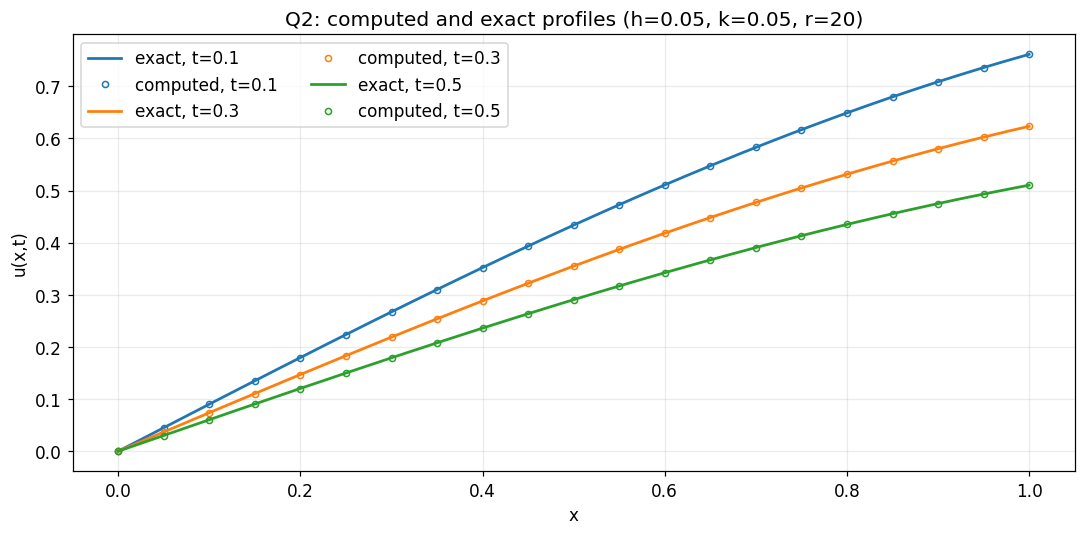

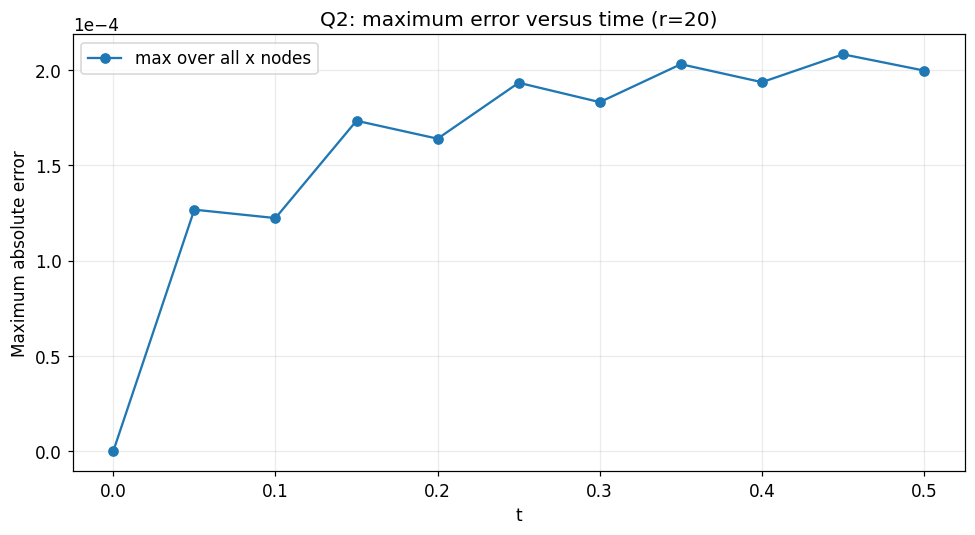

,t,r,max error
0,0.00000000e+00,2.00000000e+01,0.00000000e+00
1,5.00000000e-02,2.00000000e+01,1.26737463e-04
2,1.00000000e-01,2.00000000e+01,1.22321674e-04
3,1.50000000e-01,2.00000000e+01,1.73362490e-04
4,2.00000000e-01,2.00000000e+01,1.63955033e-04
5,2.50000000e-01,2.00000000e+01,1.93280418e-04
6,3.00000000e-01,2.00000000e+01,1.83126454e-04
7,3.50000000e-01,2.00000000e+01,2.03019714e-04
8,4.00000000e-01,2.00000000e+01,1.93591607e-04
9,4.50000000e-01,2.00000000e+01,2.08199361e-04


In [13]:
h2, k2 = 0.05, 0.05
exact2 = lambda x, t: np.exp(-t) * np.sin(x)
x2, times2, U2 = mixed_cn(h2, k2)
show_1d_tables(x2, times2, U2, exact2, [0.1, 0.3, 0.5], h2, k2)
profile_plot(x2, times2, U2, exact2, [0.1, 0.3, 0.5],
             'Q2: computed and exact profiles (h=0.05, k=0.05, r=20)')
error2 = np.max(np.abs(U2 - np.exp(-times2[:,None]) * np.sin(x2)[None,:]), axis=1)
fig, ax = plt.subplots()
ax.plot(times2, error2, 'o-', label='max over all x nodes')
ax.set(xlabel='t', ylabel='Maximum absolute error',
       title='Q2: maximum error versus time (r=20)')
ax.ticklabel_format(axis='y', style='sci', scilimits=(0, 0))
ax.legend()
fig.tight_layout()
plt.show()
display(pd.DataFrame({'t': times2, 'r': k2/h2**2, 'max error': error2}))

## Question 3(a) - Refinement with $k=h$
At $T=0.5$, define
$$E(h,k)=\max_i|U_i(T)-e^{-T}\sin x_i|,\quad
R=E(h,k)/E(h/2,k/2),\quad p=\log_2R.$$
For second-order global error $E=O(h^2+k^2)$, the coupled refinement $k=h$ should give $R\to4$ and $p\to2$. Notice that $r=1/h$ increases on this refinement path.

In [14]:
rows3a = []
for h in [1/10, 1/20, 1/40, 1/80]:
    k = h
    x, times, U = mixed_cn(h, k)
    rows3a.append({'h': h, 'k': k, 'r': k/h**2,
                   'max error': np.max(np.abs(U[-1] - exact2(x, 0.5)))})
table3a = convergence_table(rows3a)
display(table3a)
print(f'Finest-grid observed coupled order: {table3a["observed p"].iloc[-1]:.4f}')

,h,k,r,max error,previous error / error,observed p
0,1.00000000e-01,1.00000000e-01,1.00000000e+01,8.59794033e-04,NaN,NaN
1,5.00000000e-02,5.00000000e-02,2.00000000e+01,1.99668168e-04,4.30611470e+00,2.10638675e+00
2,2.50000000e-02,2.50000000e-02,4.00000000e+01,5.05343194e-05,3.95113994e+00,1.98226894e+00
3,1.25000000e-02,1.25000000e-02,8.00000000e+01,1.27115642e-05,3.97546034e+00,1.99112193e+00


Finest-grid observed coupled order: 1.9911


### Separating spatial and temporal accuracy
The required $k=h$ study varies both variables together, so it measures their **combined** order; it cannot by itself identify separate spatial and temporal orders. To support the conclusion in each variable, we add:

1. **Spatial study:** choose $k=h^2$ ($r=1$). Then $O(k^2)=O(h^4)$ is smaller than $O(h^2)$, so the exact-solution error measures spatial order.
2. **Temporal self-convergence:** keep $h=0.05$ fixed and compare $D(k)=\|U_{h,k}(0.5)-U_{h,k/2}(0.5)\|_\infty$. Both solutions share the same spatial discretisation; $D(k)/D(k/2)\to4$ demonstrates second-order time convergence without the spatial error floor in comparison to the continuum exact solution.

In [15]:
space_rows = []
for h in [0.1, 0.05, 0.025, 0.0125]:
    k = h*h
    x, times, U = mixed_cn(h, k)
    space_rows.append({'h': h, 'k': k, 'r': k/h**2,
                       'max error': np.max(np.abs(U[-1] - exact2(x, 0.5)))})
space_table = convergence_table(space_rows)
display(Markdown('**Additional spatial study: errors at t=0.5**'))
display(space_table)

h_time = 0.05
ks = [0.05, 0.025, 0.0125, 0.00625, 0.003125]
time_solutions = [mixed_cn(h_time, k)[2][-1] for k in ks]
time_rows = []
for i, k in enumerate(ks[:-1]):
    time_rows.append({'h': h_time, 'k (coarse)': k, 'k (fine)': k/2,
                      'r (coarse)': k/h_time**2, 'r (fine)': (k/2)/h_time**2,
                      'difference D(k)': np.max(np.abs(time_solutions[i] - time_solutions[i+1]))})
time_table = pd.DataFrame(time_rows)
time_table['previous D / D'] = time_table['difference D(k)'].shift(1)/time_table['difference D(k)']
time_table['observed p'] = np.log2(time_table['previous D / D'])
display(Markdown('**Additional temporal self-convergence at t=0.5**'))
display(time_table)
print('Observed spatial order:', round(space_table['observed p'].iloc[-1], 4))
print('Observed temporal order:', round(time_table['observed p'].iloc[-1], 4))

**Additional spatial study: errors at t=0.5**

,h,k,r,max error,previous error / error,observed p
0,1.00000000e-01,1.00000000e-02,1.00000000e+00,7.08308725e-04,NaN,NaN
1,5.00000000e-02,2.50000000e-03,1.00000000e+00,1.76856390e-04,4.00499370e+00,2.00179997e+00
2,2.50000000e-02,6.25000000e-04,1.00000000e+00,4.42003493e-05,4.00124416e+00,2.00044867e+00
3,1.25000000e-02,1.56250000e-04,1.00000000e+00,1.10492288e-05,4.00031079e+00,2.00011209e+00


**Additional temporal self-convergence at t=0.5**

,h,k (coarse),k (fine),r (coarse),r (fine),difference D(k),previous D / D,observed p
0,5.00000000e-02,5.00000000e-02,2.50000000e-02,2.00000000e+01,1.00000000e+01,2.28284663e-05,NaN,NaN
1,5.00000000e-02,2.50000000e-02,1.25000000e-02,1.00000000e+01,5.00000000e+00,5.70996150e-06,3.99800705e+00,1.99928102e+00
2,5.00000000e-02,1.25000000e-02,6.25000000e-03,5.00000000e+00,2.50000000e+00,1.42724938e-06,4.00067541e+00,2.00024358e+00
3,5.00000000e-02,6.25000000e-03,3.12500000e-03,2.50000000e+00,1.25000000e+00,3.56806978e-07,4.00006016e+00,2.00002170e+00


Observed spatial order: 2.0001
Observed temporal order: 2.0


## Question 3(b) - Varying the mesh ratio at fixed $h=1/20$
For each requested $r$, use $k=rh^2$. The chosen steps divide $T=0.5$ exactly. We report the actual step and number of steps so the mesh-ratio comparison is reproducible.

,h,r,k,time steps,max error
0,5.00000000e-02,5.00000000e-01,1.25000000e-03,400,1.76804053e-04
1,5.00000000e-02,1.00000000e+00,2.50000000e-03,200,1.76856390e-04
2,5.00000000e-02,5.00000000e+00,1.25000000e-02,40,1.78530485e-04
3,5.00000000e-02,1.00000000e+01,2.50000000e-02,20,1.83204378e-04
4,5.00000000e-02,5.00000000e+01,1.25000000e-01,4,3.34355378e-04


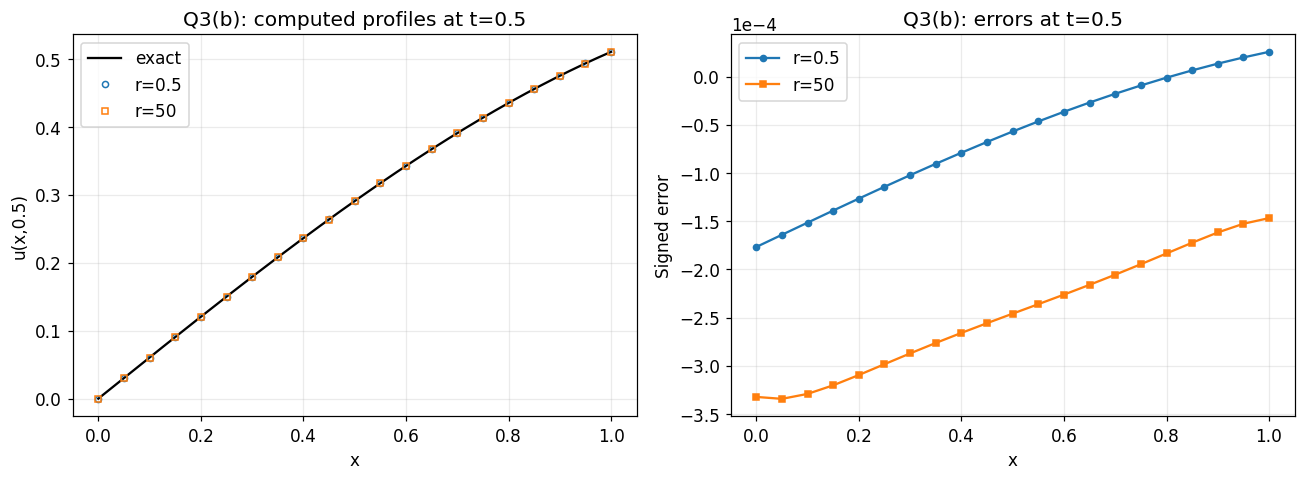

In [16]:
rows3b, profiles3b = [], {}
h3b = 1/20
for r in [0.5, 1, 5, 10, 50]:
    k = r*h3b**2
    x, times, U = mixed_cn(h3b, k)
    rows3b.append({'h': h3b, 'r': r, 'k': k, 'time steps': len(times)-1,
                   'max error': np.max(np.abs(U[-1] - exact2(x, 0.5)))})
    profiles3b[r] = U[-1].copy()
table3b = pd.DataFrame(rows3b)
display(table3b)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
xf = np.linspace(0, 1, 401)
axes[0].plot(xf, exact2(xf, 0.5), 'k-', label='exact')
for r, marker in [(0.5, 'o'), (50, 's')]:
    axes[0].plot(x, profiles3b[r], marker, ms=4, mfc='none', label=f'r={r:g}')
    axes[1].plot(x, profiles3b[r]-exact2(x, 0.5), marker+'-', ms=4, label=f'r={r:g}')
axes[0].set(xlabel='x', ylabel='u(x,0.5)', title='Q3(b): computed profiles at t=0.5')
axes[1].set(xlabel='x', ylabel='Signed error', title='Q3(b): errors at t=0.5')
axes[1].ticklabel_format(axis='y', style='sci', scilimits=(0, 0))
for ax in axes:
    ax.legend()
fig.tight_layout()
plt.show()

**Conclusion.** The error changes little for small $r$, where spatial error dominates, and increases at the larger time steps. All these runs remain stable. Unconditional stability does not imply accurate results for arbitrarily large $k$.

For a discrete mode with eigenvalue $-\lambda$, CN has amplification factor
$$q=\frac{1-k\lambda/2}{1+k\lambda/2}.$$
Although $|q|\le1$, for $k\lambda\gg1$ it approaches $-1$ rather than zero. Thus stiff grid-scale components can decay slowly and alternate sign. This explains why large mesh ratios may produce weakly damped transients for other data; the smooth profiles here do not develop a large instability. CN is A-stable but not L-stable.

## 3. Peaceman-Rachford ADI discretisation
For the two-dimensional problems let $U_{ij}\approx u(x_i,y_j,t)$ and
$$\dot U=L_xU+L_yU+B(t).$$
The one-dimensional ghost-node operator is applied in each coordinate. In Question 4, $B=0$. In Question 5, only the $x$ boundary data are inhomogeneous, with
$$B_{0j}(t)=-2g_0(y_j,t)/h,\qquad B_{Nj}(t)=2g_1(y_j,t)/h.$$
The $y$ derivative conditions are homogeneous in both questions.

Set $a=k/2$, $B_m=B(t_n+k/2)$, and use the Peaceman-Rachford steps
$$\boxed{(I-aL_x)U^*=(I+aL_y)U^n+aB_m,}$$
$$\boxed{(I-aL_y)U^{n+1}=(I+aL_x)U^*+aB_m.}$$
Each stage solves independent tridiagonal line systems. The first solves in $x$ for every $y$; the second solves in $y$ for every $x$. No full two-dimensional matrix is constructed.

**Time-dependent boundaries:** the same midpoint boundary source appears in both half-steps. $U^*$ is an algebraic ADI stage, not an exact solution at $t_n+k/2$; we do not overwrite its boundary values using the exact solution. This source formulation treats the nonhomogeneous derivative conditions consistently with the splitting.

For fixed spatial mesh, expansion gives
$$U^{n+1}=U^n+k[(L_x+L_y)U^n+B_n]
+\frac{k^2}{2}[(L_x+L_y)^2U^n+(L_x+L_y)B_n+B'_n]+O(k^3),$$
so the time discretisation is second order. For a homogeneous separable mode, its amplification factor is the product of the two one-dimensional CN factors.

In [17]:
def pr_adi(h, k, T, initial, exact, alpha_x=0.0, x_boundary=None,
           save_times=()):
    # U[i,j] = U(x_i,y_j); y boundaries are homogeneous Neumann.
    x, y, times = grid_1d(h), grid_1d(h), time_grid(T, k)
    X, Y = np.meshgrid(x, y, indexing='ij')
    Lx, Ly = second_difference(h, alpha_x), second_difference(h)
    a = k / 2.0
    solve_x, solve_y = implicit_factor(Lx, a), implicit_factor(Ly, a)
    U = initial(X, Y)
    save_steps = {int(round(t / k)) for t in save_times}
    for t in save_times:
        if not np.isclose(round(t / k) * k, t) or not (0 <= t <= T):
            raise ValueError('Each snapshot must lie on the time grid.')
    snapshots = {0: U.copy()} if 0 in save_steps else {}
    errors = np.empty(len(times))
    errors[0] = np.max(np.abs(U - exact(X, Y, 0.0)))
    for n in range(len(times) - 1):
        midpoint = (times[n] + times[n + 1]) / 2.0
        B = np.zeros_like(U)
        if x_boundary is not None:
            g0, g1 = x_boundary(y, midpoint)
            B[0, :], B[-1, :] = -2.0 * g0 / h, 2.0 * g1 / h
        # Stage 1: implicit in x, explicit in y.
        rhs_x = U + a * tri_apply(Ly, U.T).T + a * B
        intermediate = solve_x.solve(rhs_x)
        # Stage 2: explicit in x, implicit in y.
        rhs_y = intermediate + a * tri_apply(Lx, intermediate) + a * B
        U = solve_y.solve(rhs_y.T).T
        errors[n + 1] = np.max(np.abs(U - exact(X, Y, times[n + 1])))
        if n + 1 in save_steps:
            snapshots[n + 1] = U.copy()
    return x, y, times, U, snapshots, errors

exact4 = lambda X,Y,t: np.exp(-2*np.pi**2*t)*np.cos(np.pi*X)*np.cos(np.pi*Y)
exact5 = lambda X,Y,t: np.exp(-(1+np.pi**2)*t)*np.sin(X)*np.cos(np.pi*Y)
bc5 = lambda y,t: (np.exp(-(1+np.pi**2)*t)*np.cos(np.pi*y), (np.cos(1)+np.sin(1))*np.exp(-(1+np.pi**2)*t)*np.cos(np.pi*y))

In [18]:
def show_adi_lines(result, exact, requested_times, requested_y, h, k, label):
    x, y, times, final, snapshots, errors = result
    for t in requested_times:
        n = time_index(times, t)
        for y_value in requested_y:
            j = int(round(y_value/h))
            if not np.isclose(y[j], y_value):
                raise ValueError('Requested line is not on the spatial grid.')
            display(Markdown(f'**{label}: t={t:g}, y={y_value:g}; '
                             f'h={h:g}, k={k:g}, r={k/h**2:g}**'))
            display(value_table(x, snapshots[n][:, j], exact(x, y[j], t)))

def contour_solution_error(result, exact, T, title):
    x, y, times, final, snapshots, errors = result
    X, Y = np.meshgrid(x, y, indexing='ij')
    signed_error = final - exact(X, Y, T)
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
    for ax, values, label in zip(axes, [final, signed_error],
                                ['Computed solution', 'Signed error U - exact']):
        contour = ax.contourf(X, Y, values, levels=21, cmap='coolwarm')
        ax.set(xlabel='x', ylabel='y', title=label, aspect='equal')
        ax.grid(False)
        fig.colorbar(contour, ax=ax, format='%.2e')
    fig.suptitle(title)
    fig.tight_layout()
    plt.show()

## Question 4 - ADI with homogeneous Neumann conditions
$$u_t=u_{xx}+u_{yy},\qquad u(x,y,0)=\cos(\pi x)\cos(\pi y),$$
with zero normal derivative on all four edges. The exact solution is
$$u(x,y,t)=e^{-2\pi^2t}\cos(\pi x)\cos(\pi y).$$
The requested grids are
- coarse: $h=0.05$, $k=0.001$, $r=0.4$;
- fine: $h=0.025$, $k=0.00025$, $r=0.4$.

**The requested line is a nodal line:** $\cos(\pi/2)=0$, so the exact solution on $y=0.5$ vanishes for every $x$ and $t$. The computed values there should be roundoff-sized. These line tables cannot measure the nonzero global discretisation error; use the full-grid maximum error for the convergence study.

**Q4 coarse: t=0.01, y=0.5; h=0.05, k=0.001, r=0.4**

,x,computed U,exact u,signed error,absolute error
0,0.00000000e+00,-8.67361738e-17,5.02637124e-17,-1.36999886e-16,1.36999886e-16
1,5.00000000e-02,-8.32667268e-17,4.96448827e-17,-1.32911610e-16,1.32911610e-16
2,1.00000000e-01,-8.67361738e-17,4.78036312e-17,-1.34539805e-16,1.34539805e-16
3,1.50000000e-01,-7.97972799e-17,4.47852956e-17,-1.24582576e-16,1.24582576e-16
4,2.00000000e-01,-6.59194921e-17,4.06641975e-17,-1.06583690e-16,1.06583690e-16
5,2.50000000e-01,-5.03069808e-17,3.55418119e-17,-8.58487927e-17,8.58487927e-17
6,3.00000000e-01,-4.68375339e-17,2.95442689e-17,-7.63818027e-17,7.63818027e-17
7,3.50000000e-01,-3.98986399e-17,2.28192479e-17,-6.27178878e-17,6.27178878e-17
8,4.00000000e-01,-2.94902991e-17,1.55323413e-17,-4.50226404e-17,4.50226404e-17
9,4.50000000e-01,-1.51788304e-17,7.86297695e-18,-2.30418074e-17,2.30418074e-17


**Q4 coarse: t=0.05, y=0.5; h=0.05, k=0.001, r=0.4**

,x,computed U,exact u,signed error,absolute error
0,0.00000000e+00,-3.38271078e-16,2.28217731e-17,-3.61092851e-16,3.61092851e-16
1,5.00000000e-02,-3.36536354e-16,2.25407992e-17,-3.59077154e-16,3.59077154e-16
2,1.00000000e-01,-3.24393290e-16,2.17047960e-17,-3.46098086e-16,3.46098086e-16
3,1.50000000e-01,-3.02709247e-16,2.03343487e-17,-3.23043595e-16,3.23043595e-16
4,2.00000000e-01,-2.72351586e-16,1.84632023e-17,-2.90814788e-16,2.90814788e-16
5,2.50000000e-01,-2.35922393e-16,1.61374305e-17,-2.52059823e-16,2.52059823e-16
6,3.00000000e-01,-1.92554306e-16,1.34143017e-17,-2.05968607e-16,2.05968607e-16
7,3.50000000e-01,-1.49619900e-16,1.03608682e-17,-1.59980768e-16,1.59980768e-16
8,4.00000000e-01,-1.00613962e-16,7.05231573e-18,-1.07666277e-16,1.07666277e-16
9,4.50000000e-01,-5.00901404e-17,3.57011187e-18,-5.36602522e-17,5.36602522e-17


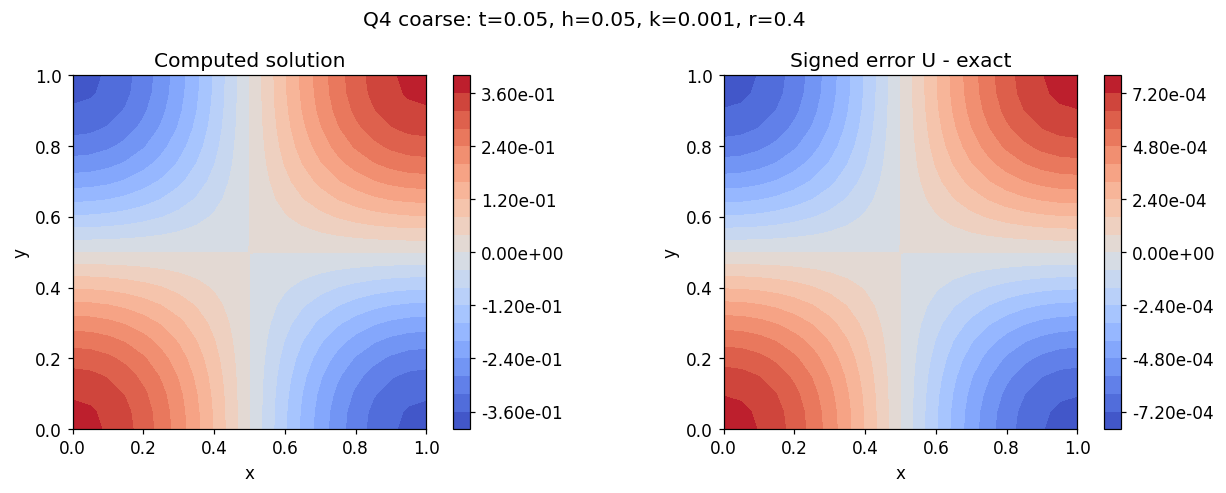

**Q4 fine: t=0.01, y=0.5; h=0.025, k=0.00025, r=0.4**

,x,computed U,exact u,signed error,absolute error
0,0.00000000e+00,-2.25514052e-17,5.02637124e-17,-7.28151176e-17,7.28151176e-17
1,2.50000000e-02,-2.42861287e-17,5.01087661e-17,-7.43948948e-17,7.43948948e-17
2,5.00000000e-02,-3.29597460e-17,4.96448827e-17,-8.26046287e-17,8.26046287e-17
3,7.50000000e-02,-3.64291930e-17,4.88749220e-17,-8.53041150e-17,8.53041150e-17
4,1.00000000e-01,-4.33680869e-17,4.78036312e-17,-9.11717181e-17,9.11717181e-17
5,1.25000000e-01,-4.33680869e-17,4.64376151e-17,-8.98057020e-17,8.98057020e-17
6,1.50000000e-01,-3.98986399e-17,4.47852956e-17,-8.46839356e-17,8.46839356e-17
7,1.75000000e-01,-3.81639165e-17,4.28568600e-17,-8.10207764e-17,8.10207764e-17
8,2.00000000e-01,-3.72965547e-17,4.06641975e-17,-7.79607522e-17,7.79607522e-17
9,2.25000000e-01,-3.64291930e-17,3.82208267e-17,-7.46500197e-17,7.46500197e-17


**Q4 fine: t=0.05, y=0.5; h=0.025, k=0.00025, r=0.4**

,x,computed U,exact u,signed error,absolute error
0,0.00000000e+00,-7.45931095e-16,2.28217731e-17,-7.68752868e-16,7.68752868e-16
1,2.50000000e-02,-7.44196371e-16,2.27514212e-17,-7.66947792e-16,7.66947792e-16
2,5.00000000e-02,-7.36390116e-16,2.25407992e-17,-7.58930915e-16,7.58930915e-16
3,7.50000000e-02,-7.22512328e-16,2.21912057e-17,-7.44703533e-16,7.44703533e-16
4,1.00000000e-01,-7.06032455e-16,2.17047960e-17,-7.27737251e-16,7.27737251e-16
5,1.25000000e-01,-6.86083135e-16,2.10845691e-17,-7.07167704e-16,7.07167704e-16
6,1.50000000e-01,-6.59628602e-16,2.03343487e-17,-6.79962950e-16,6.79962950e-16
7,1.75000000e-01,-6.28837260e-16,1.94587604e-17,-6.48296020e-16,6.48296020e-16
8,2.00000000e-01,-5.96311195e-16,1.84632023e-17,-6.14774397e-16,6.14774397e-16
9,2.25000000e-01,-5.60749364e-16,1.73538124e-17,-5.78103176e-16,5.78103176e-16


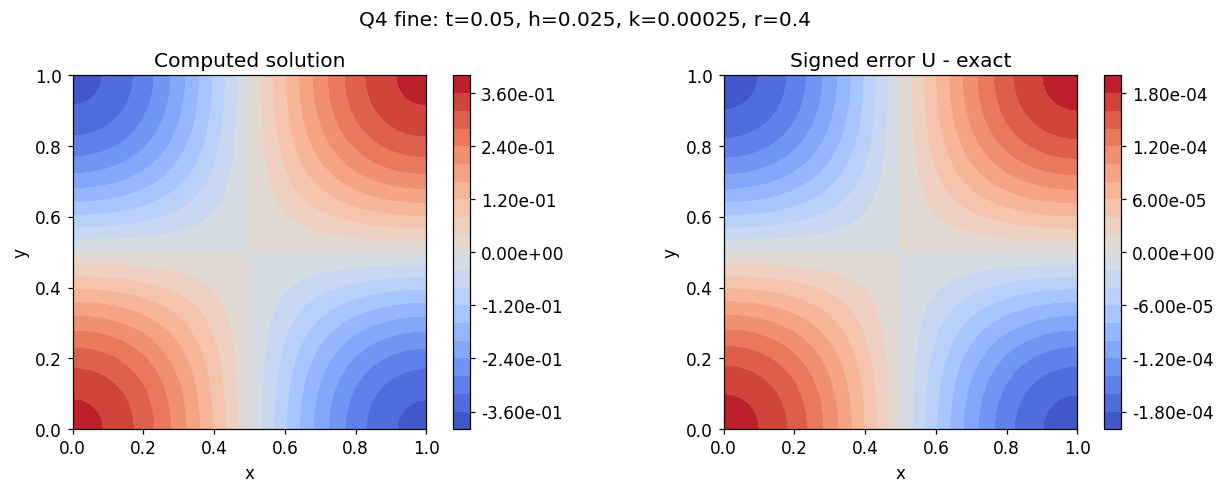

In [19]:
q4_results = {}
for h, k, name in [(0.05, 0.001, 'coarse'), (0.025, 0.00025, 'fine')]:
    result = pr_adi(h, k, 0.05,
                    lambda X,Y: np.cos(np.pi*X)*np.cos(np.pi*Y),
                    exact4, save_times=[0.01, 0.05])
    q4_results[name] = result
    show_adi_lines(result, exact4, [0.01, 0.05], [0.5], h, k, f'Q4 {name}')
    contour_solution_error(result, exact4, 0.05,
                            f'Q4 {name}: t=0.05, h={h:g}, k={k:g}, r={k/h**2:g}')

### Full-grid convergence and exact discrete-mode check
For each mesh the initial product of cosines is an exact discrete eigenmode. With
$$\lambda_h=4h^{-2}\sin^2(\pi h/2),\qquad
q_h=\frac{1-k\lambda_h/2}{1+k\lambda_h/2},$$
ADI gives
$$U_{ij}^{n}=q_h^{2n}\cos(\pi x_i)\cos(\pi y_j).$$
We compare the implementation with this discrete formula and calculate the convergence order from full-grid errors at both requested times.

In [20]:
q4_rows, q4_mode_residuals = [], []
for T in [0.01, 0.05]:
    errors_at_T = []
    for h, k, name in [(0.05, 0.001, 'coarse'), (0.025, 0.00025, 'fine')]:
        x, y, times, final, snaps, errs = q4_results[name]
        n = time_index(times, T)
        X, Y = np.meshgrid(x, y, indexing='ij')
        E = np.max(np.abs(snaps[n] - exact4(X, Y, T)))
        errors_at_T.append(E)
        lam = 4/h**2 * np.sin(np.pi*h/2)**2
        q = (1-k*lam/2)/(1+k*lam/2)
        mode_residual = np.max(np.abs(snaps[n] - q**(2*n)*np.cos(np.pi*X)*np.cos(np.pi*Y)))
        q4_mode_residuals.append(mode_residual)
        q4_rows.append({'t': T, 'mesh': name, 'h': h, 'k': k, 'r': k/h**2,
                        'full-grid max error': E,
                        'mode check difference': mode_residual})
    ratio = errors_at_T[0]/errors_at_T[1]
    print(f't={T:g}: coarse/fine error ratio = {ratio:.6f}; observed order in h = {np.log2(ratio):.6f}')
q4_table = pd.DataFrame(q4_rows)
display(q4_table)
assert max(q4_mode_residuals) < 2e-12

t=0.01: coarse/fine error ratio = 3.986367; observed order in h = 1.995075
t=0.05: coarse/fine error ratio = 3.988781; observed order in h = 1.995948


,t,mesh,h,k,r,full-grid max error,mode check difference
0,1.00000000e-02,coarse,5.00000000e-02,1.00000000e-03,4.00000000e-01,3.31652844e-04,9.99200722e-16
1,1.00000000e-02,fine,2.50000000e-02,2.50000000e-04,4.00000000e-01,8.31967579e-05,9.76996262e-15
2,5.00000000e-02,coarse,5.00000000e-02,1.00000000e-03,4.00000000e-01,7.53528157e-04,2.66453526e-15
3,5.00000000e-02,fine,2.50000000e-02,2.50000000e-04,4.00000000e-01,1.88911876e-04,2.27595720e-14


**Observed order.** The error ratio is close to four, giving order approximately two with respect to $h$. On this path, $h\mapsto h/2$ and $k\mapsto k/4$, so the spatial contribution $O(h^2)$ decreases by four, whereas the temporal contribution $O(k^2)$ decreases by sixteen. The observed result is consistent with a spatially dominated $O(h^2+k^2)$ error. It does not independently measure temporal order.

## Question 5 - ADI with mixed derivative conditions
$$u_t=u_{xx}+u_{yy},\qquad u(x,y,0)=\sin x\cos(\pi y),$$
$$u_x(0,y,t)=e^{-(1+\pi^2)t}\cos(\pi y),$$
$$u_x(1,y,t)+u(1,y,t)=(\cos1+\sin1)e^{-(1+\pi^2)t}\cos(\pi y),$$
with $u_y=0$ at $y=0,1$. The exact solution is
$$u(x,y,t)=e^{-(1+\pi^2)t}\sin x\cos(\pi y).$$
Use $h=0.05$, $k=0.002$, hence $\boxed{r=0.8}$. The $x$ operator has $\alpha_x=1$ and the $y$ operator has $\alpha_y=0$. Insert the prescribed $g_0(y,t)$ and $g_1(y,t)$ into $B(t)$ and evaluate at the midpoint in each ADI step.

The line $y=0.5$ is again identically zero in the exact solution. The $y=0$ tables and full-grid maximum errors reveal the actual discretisation error.

**Q5: t=0.05, y=0; h=0.05, k=0.002, r=0.8**

,x,computed U,exact u,signed error,absolute error
0,0.00000000e+00,2.95650748e-05,0.00000000e+00,2.95650748e-05,2.95650748e-05
1,5.00000000e-02,2.90699558e-02,2.90240874e-02,4.58684734e-05,4.58684734e-05
2,1.00000000e-01,5.80420333e-02,5.79756296e-02,6.64036799e-05,6.64036799e-05
3,1.50000000e-01,8.68722484e-02,8.67822630e-02,8.99854388e-05,8.99854388e-05
4,2.00000000e-01,1.15487617e-01,1.15371986e-01,1.15631011e-04,1.15631011e-04
5,2.50000000e-01,1.43815884e-01,1.43673339e-01,1.42545238e-04,1.42545238e-04
6,3.00000000e-01,1.71785682e-01,1.71615583e-01,1.70098822e-04,1.70098822e-04
7,3.50000000e-01,1.99326680e-01,1.99128878e-01,1.97801603e-04,1.97801603e-04
8,4.00000000e-01,2.26369727e-01,2.26144455e-01,2.25272585e-04,2.25272585e-04
9,4.50000000e-01,2.52846996e-01,2.52594788e-01,2.52208246e-04,2.52208246e-04


**Q5: t=0.05, y=0.5; h=0.05, k=0.002, r=0.8**

,x,computed U,exact u,signed error,absolute error
0,0.00000000e+00,1.40738759e-17,0.00000000e+00,1.40738759e-17,1.40738759e-17
1,5.00000000e-02,1.47451495e-17,1.77721278e-18,1.29679368e-17,1.29679368e-17
2,1.00000000e-01,1.51788304e-17,3.54998346e-18,1.16288470e-17,1.16288470e-17
3,1.50000000e-01,1.47451495e-17,5.31388103e-18,9.43126852e-18,9.43126852e-18
4,2.00000000e-01,1.38777878e-17,7.06449666e-18,6.81329114e-18,6.81329114e-18
5,2.50000000e-01,1.47451495e-17,8.79745473e-18,5.94769481e-18,5.94769481e-18
6,3.00000000e-01,1.82145965e-17,1.05084237e-17,7.70617275e-18,7.70617275e-18
7,3.50000000e-01,1.90819582e-17,1.21931272e-17,6.88883106e-18,6.88883106e-18
8,4.00000000e-01,2.25514052e-17,1.38473541e-17,8.70405105e-18,8.70405105e-18
9,4.50000000e-01,2.25514052e-17,1.54669699e-17,7.08443526e-18,7.08443526e-18


**Q5: t=0.1, y=0; h=0.05, k=0.002, r=0.8**

,x,computed U,exact u,signed error,absolute error
0,0.00000000e+00,1.06062089e-04,0.00000000e+00,1.06062089e-04,1.06062089e-04
1,5.00000000e-02,1.69714320e-02,1.68549750e-02,1.16457044e-04,1.16457044e-04
2,1.00000000e-01,3.37989514e-02,3.36678213e-02,1.31130129e-04,1.31130129e-04
3,1.50000000e-01,5.05458089e-02,5.03965156e-02,1.49293351e-04,1.49293351e-04
4,2.00000000e-01,6.71694597e-02,6.69992448e-02,1.70214890e-04,1.70214890e-04
5,2.50000000e-01,8.36277283e-02,8.34345109e-02,1.93217400e-04,1.93217400e-04
6,3.00000000e-01,9.98789082e-02,9.96612341e-02,2.17674121e-04,2.17674121e-04
7,3.50000000e-01,1.15881859e-01,1.15638856e-01,2.43003052e-04,2.43003052e-04
8,4.00000000e-01,1.31596101e-01,1.31327441e-01,2.68659477e-04,2.68659477e-04
9,4.50000000e-01,1.46981903e-01,1.46687776e-01,2.94127190e-04,2.94127190e-04


**Q5: t=0.1, y=0.5; h=0.05, k=0.002, r=0.8**

,x,computed U,exact u,signed error,absolute error
0,0.00000000e+00,4.48580179e-17,0.00000000e+00,4.48580179e-17,4.48580179e-17
1,5.00000000e-02,4.54280710e-17,1.03206956e-18,4.43960015e-17,4.43960015e-17
2,1.00000000e-01,4.70543743e-17,2.06155948e-18,4.49928148e-17,4.49928148e-17
3,1.50000000e-01,4.90059382e-17,3.08589657e-18,4.59200416e-17,4.59200416e-17
4,2.00000000e-01,5.20417043e-17,4.10252054e-18,4.79391837e-17,4.79391837e-17
5,2.50000000e-01,5.46437895e-17,5.10889033e-18,4.95348992e-17,4.95348992e-17
6,3.00000000e-01,5.94142791e-17,6.10249057e-18,5.33117885e-17,5.33117885e-17
7,3.50000000e-01,6.50521303e-17,7.08083775e-18,5.79712926e-17,5.79712926e-17
8,4.00000000e-01,6.85215773e-17,8.04148653e-18,6.04800908e-17,6.04800908e-17
9,4.50000000e-01,7.71951947e-17,8.98203577e-18,6.82131589e-17,6.82131589e-17


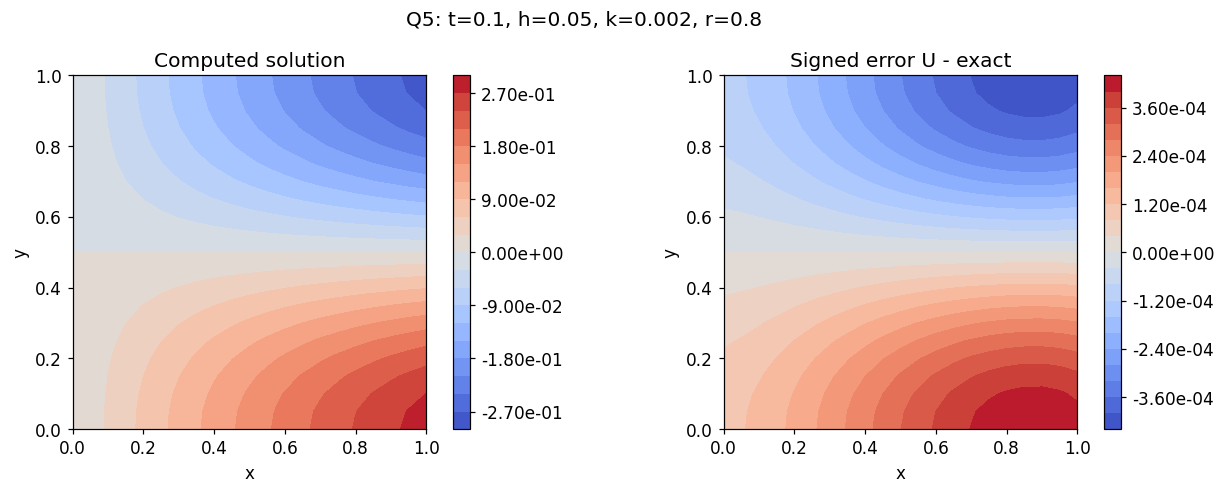

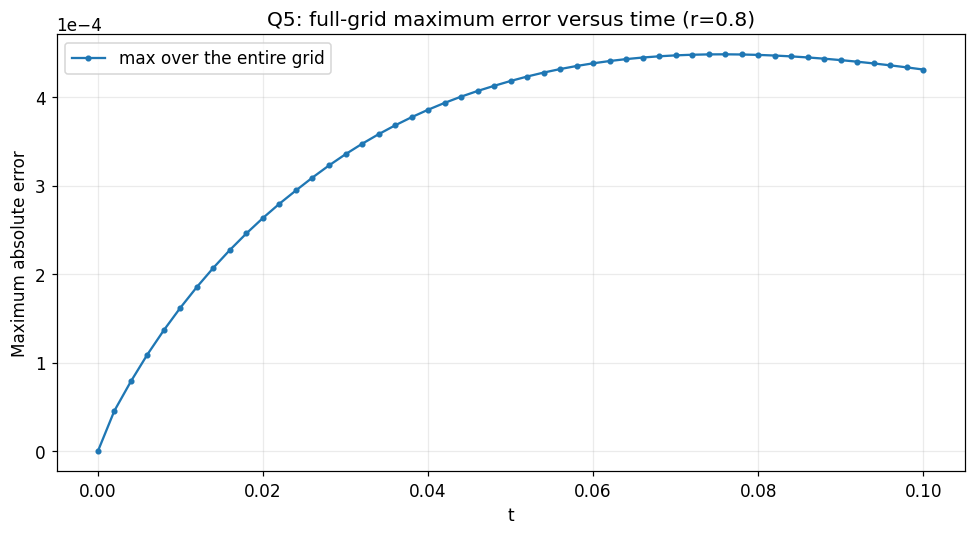

,t,r,full-grid max error
0,0.00000000e+00,8.00000000e-01,0.00000000e+00
1,2.00000000e-03,8.00000000e-01,4.57083234e-05
2,4.00000000e-03,8.00000000e-01,7.89392273e-05
3,6.00000000e-03,8.00000000e-01,1.09322004e-04
4,8.00000000e-03,8.00000000e-01,1.36850933e-04
5,1.00000000e-02,8.00000000e-01,1.62191063e-04
6,1.20000000e-02,8.00000000e-01,1.85600113e-04
7,1.40000000e-02,8.00000000e-01,2.07292937e-04
8,1.60000000e-02,8.00000000e-01,2.27426170e-04
9,1.80000000e-02,8.00000000e-01,2.46127716e-04


In [21]:
h5, k5 = 0.05, 0.002
result5 = pr_adi(h5, k5, 0.1, lambda X,Y: np.sin(X)*np.cos(np.pi*Y),
                 exact5, alpha_x=1.0, x_boundary=bc5,
                 save_times=[0.05, 0.1])
show_adi_lines(result5, exact5, [0.05, 0.1], [0.0, 0.5], h5, k5, 'Q5')
contour_solution_error(result5, exact5, 0.1,
                        'Q5: t=0.1, h=0.05, k=0.002, r=0.8')
x5, y5, times5, final5, snaps5, errors5 = result5
fig, ax = plt.subplots()
ax.plot(times5, errors5, 'o-', ms=3, label='max over the entire grid')
ax.set(xlabel='t', ylabel='Maximum absolute error',
       title='Q5: full-grid maximum error versus time (r=0.8)')
ax.ticklabel_format(axis='y', style='sci', scilimits=(0, 0))
ax.legend()
fig.tight_layout()
plt.show()
display(pd.DataFrame({'t': times5, 'r': k5/h5**2, 'full-grid max error': errors5}))

### Conclusions
- CN with the second-order ghost derivative boundary conditions gives approximately second-order global spatial and temporal accuracy for Question 2. The additional studies separate those two claims.
- Increasing $r$ at fixed $h$ increases $k$. The tested solutions remain stable, but the larger steps have greater temporal error; CN does not strongly damp the stiffest modes.
- The PR ADI method uses only tridiagonal line solves. The Question 4 full-grid error decreases by approximately four under the specified mesh refinement, consistent with second-order spatial accuracy.
- The requested $y=0.5$ line tables in Questions 4 and 5 are near zero because of the exact cosine factor. They should not be used to estimate the nonzero full-grid error or convergence order.
- The inhomogeneous Neumann/Robin conditions are included through boundary source terms, with trapezoidal time averaging for CN and midpoint source splitting for ADI.